In [53]:
import numpy as np
import matplotlib.pyplot as plt


def grad(H, w):
    return H@w


def loss(H, w):
    return 0.5 * w.T @ H @ w


num_runs = 100
num_iters_per_run = 100
d = 100
B = 10
variances = np.ones(d) # Components of noise have generic variances
noise_std = np.sqrt(variances / B) # Effect on SGD scales with sqrt(B)

# Use A = I
A = np.identity(d)

# Use A = X^TX / n
# n = 10000
# X = np.random.randn(n, d)
# A = X.T @ X / n

eigenvalues, eigenvectors = np.linalg.eigh(A)
H = np.diag(eigenvalues)
w_init = np.random.randn(d)

In [54]:
eta = 1 / np.max(eigenvalues)
loss_values = []

for _ in range(num_runs):
    w_k = w_init.copy()
    for _ in range(num_iters_per_run):
        loss_values.append(loss(H, w_k))
        w_k -= eta * (grad(H, w_k) + np.random.normal(scale=noise_std, size=d))

bounded_loss_values = [(1 - eta * np.min(eigenvalues)) ** (2 * k) * loss(H, w_init) + (eta * d * np.max(variances)) / (2 * B) for k in range(num_iters_per_run)]


loss_values = np.array(loss_values).reshape(num_runs, num_iters_per_run)
loss_values = np.mean(loss_values, axis=0)

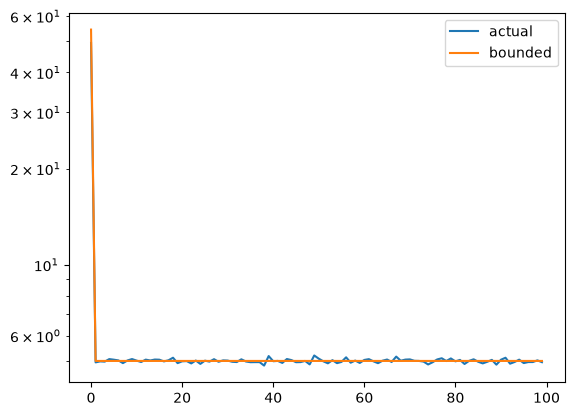

In [55]:
plt.plot(loss_values, label="actual")
plt.plot(bounded_loss_values, label="bounded")
plt.legend()
plt.semilogy()
plt.show()